# Taxis NYC · Preparacion

## 1. Pronostico

### Librerias y carpetas

In [1]:
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Carpetas del proyecto:
CARPETA_DATOS = Path("datos")
CARPETA_API = Path("api")
CARPETA_APP_DATA = Path("app") / "data"
for carpeta in [CARPETA_DATOS, CARPETA_API, CARPETA_APP_DATA]:
    carpeta.mkdir(parents=True, exist_ok=True)

print("xgboost", xgb.__version__, "| pandas", pd.__version__)

xgboost 3.4.1 | pandas 3.0.5


### Descargar y leer los datos

In [2]:
URL_VIAJES = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2024-01.parquet"
URL_ZONAS = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
archivo_viajes = CARPETA_DATOS / "yellow_tripdata_2024-01.parquet"
archivo_zonas = CARPETA_DATOS / "taxi_zone_lookup.csv"

# Se agrega el if not para no descargarlo nuevamente si ya existe
if not archivo_viajes.exists():
    urllib.request.urlretrieve(URL_VIAJES, archivo_viajes)
if not archivo_zonas.exists():
    urllib.request.urlretrieve(URL_ZONAS, archivo_zonas)

# Importamos solo las columnas a utilizar
columnas = ["tpep_pickup_datetime", "PULocationID", "trip_distance", "fare_amount", "tip_amount"]
viajes = pd.read_parquet(archivo_viajes, columns=columnas)
zonas = pd.read_csv(archivo_zonas)
print(viajes.shape)
viajes.head()

(2964624, 5)


,tpep_pickup_datetime,PULocationID,trip_distance,fare_amount,tip_amount
0,2024-01-01 00:57:55,186,1.72,17.7,0.00
1,2024-01-01 00:03:00,140,1.80,10.0,3.75
2,2024-01-01 00:17:06,236,4.70,23.3,3.00
3,2024-01-01 00:36:38,79,1.40,10.0,2.00
4,2024-01-01 00:46:51,211,0.80,7.9,3.20


### Filtrar viajes validos

In [3]:
INICIO = pd.Timestamp("2024-01-01")
FIN_ENERO = pd.Timestamp("2024-02-01")

print("Fecha minima:", viajes["tpep_pickup_datetime"].min())
print("Fecha maxima:", viajes["tpep_pickup_datetime"].max())

dentro = (viajes["tpep_pickup_datetime"] >= INICIO) & (viajes["tpep_pickup_datetime"] < FIN_ENERO)
print("Viajes fuera de enero:", (~dentro).sum())
viajes = viajes[dentro]
print("Viajes validos:", len(viajes))

Fecha minima: 2002-12-31 22:59:39
Fecha maxima: 2024-02-01 00:01:15
Viajes fuera de enero: 18


Viajes validos: 2964606


### Filtrar zonas validas

In [4]:
# Eliminamos zonas desconocidas o fuera de NY: 264 = desconocida, 265 = fuera de NYC
print(zonas.tail(3))
ZONAS_DESCONOCIDAS = [264, 265]

# Tabla de nombres: LocationID --> nombre y distrito
nombres = zonas.set_index("LocationID").rename(columns={"Zone": "nombre", "Borough": "distrito"})
nombres = nombres[["nombre", "distrito"]]

conteo = viajes["PULocationID"].value_counts().drop(ZONAS_DESCONOCIDAS, errors="ignore")
zonas_pronostico = sorted(conteo[conteo >= 3000].index.tolist())
print("Zonas que se pronostican:", len(zonas_pronostico))
conteo.head(5).to_frame("viajes").join(nombres)

     LocationID    Borough            Zone service_zone
262         263  Manhattan  Yorkville West  Yellow Zone
263         264    Unknown             NaN          NaN
264         265        NaN  Outside of NYC          NaN
Zonas que se pronostican: 58


,viajes,nombre,distrito
PULocationID,,,
132,145240,JFK Airport,Queens
161,143469,Midtown Center,Manhattan
237,142707,Upper East Side South,Manhattan
236,136464,Upper East Side North,Manhattan
162,106717,Midtown East,Manhattan


### Convertir series de tiempo

In [5]:
# Redondear la hora de inicio de cada viaje a la hora 00
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")

# Contar viajes por zona y hora
de_zonas = viajes[viajes["PULocationID"].isin(zonas_pronostico)]
conteo_hora = de_zonas.groupby(["PULocationID", "hora"]).size()
print("Combinaciones zona-hora con al menos un viaje:", len(conteo_hora))

# Todas las combinaciones zona-hora, del 1 de enero al 1 de febrero a las 23:00
horas = pd.date_range("2024-01-01 00:00", "2024-02-01 23:00", freq="h")
indice = pd.MultiIndex.from_product([zonas_pronostico, horas], names=["PULocationID", "hora"])
demanda = conteo_hora.reindex(indice, fill_value=0).rename("viajes").reset_index()

# El 1 de febrero es el "mañana" y no sabemos cuantos viajes habra
demanda["viajes"] = demanda["viajes"].astype(float)
demanda.loc[demanda["hora"] >= FIN_ENERO, "viajes"] = np.nan

print("Filas:", len(demanda), "=", len(zonas_pronostico), "zonas x", len(horas), "horas")
print("Horas de enero rellenadas con 0:", (demanda["viajes"] == 0).sum())

Combinaciones zona-hora con al menos un viaje: 41359
Filas: 44544 = 58 zonas x 768 horas
Horas de enero rellenadas con 0: 1793


### Variables lag y calendario

In [6]:
# Variables - Ordenar por zona y hora es obligatorio antes de usar shift para no mezclar zonas
demanda = demanda.sort_values(["PULocationID", "hora"]).reset_index(drop=True)
por_zona = demanda.groupby("PULocationID")["viajes"]
for lag in [24, 48, 167, 168, 169]:
    demanda[f"lag_{lag}"] = por_zona.shift(lag)

# Promedio de viajes por hora del dia anterior
demanda["fecha"] = demanda["hora"].dt.normalize()
media_dia = demanda.groupby(["PULocationID", "fecha"])["viajes"].mean()
media_dia = media_dia.rename("media_dia_ant").reset_index()
media_dia["fecha"] = media_dia["fecha"] + pd.Timedelta(days=1)  # el promedio de ayer se usa hoy
demanda = demanda.merge(media_dia, on=["PULocationID", "fecha"], how="left")

# Calendario - El 1 de enero tambien es feriado (Año Nuevo)
FERIADOS = pd.to_datetime(["2024-01-01", "2024-01-15"])
demanda["hora_del_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.dayofweek  # 0 = lunes ... 6 = domingo
demanda["feriado"] = demanda["fecha"].isin(FERIADOS).astype(int)

# La zona como categoria - XGBoost la entiende sin convertirla en 58 columnas
demanda["zona"] = pd.Categorical(demanda["PULocationID"], categories=zonas_pronostico)

VARIABLES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169", "media_dia_ant",
             "hora_del_dia", "dia_semana", "feriado", "zona"]

# Comprobacion con el ejemplo del PDF: Midtown Center (161), 25 de enero a las 17:00
fila = demanda[(demanda["PULocationID"] == 161) & (demanda["hora"] == "2024-01-25 17:00")]
fila[["hora", "viajes"] + VARIABLES]

,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_del_dia,dia_semana,feriado,zona
25937,2024-01-25 17:00:00,580.0,625.0,561.0,709.0,623.0,482.0,269.625,17,3,0,161


### Separar por entrenamiento, prueba y futuro

In [7]:
FIN_TRAIN = pd.Timestamp("2024-01-25")  # entrenamiento hasta el 24 de enero

# Las primeras 169 horas de cada zona no tienen lag_169, no sirven para entrenar
con_lags = demanda.dropna(subset=VARIABLES)

train = con_lags[con_lags["hora"] < FIN_TRAIN]
test = con_lags[(con_lags["hora"] >= FIN_TRAIN) & (con_lags["hora"] < FIN_ENERO)]
futuro = con_lags[con_lags["hora"] >= FIN_ENERO]

for nombre, parte in [("Entrenamiento", train), ("Prueba", test), ("Futuro", futuro)]:
    print(f"{nombre:14} {len(parte):6} filas  {parte['hora'].min()} -> {parte['hora'].max()}")

Entrenamiento   23606 filas  2024-01-08 01:00:00 -> 2024-01-24 23:00:00
Prueba           9744 filas  2024-01-25 00:00:00 -> 2024-01-31 23:00:00
Futuro           1392 filas  2024-02-01 00:00:00 -> 2024-02-01 23:00:00


### crear el modelo, predecir y medir el error

In [8]:
CUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

def crear_modelo(learning_rate):
    return xgb.XGBRegressor(
        objective="reg:quantileerror",       # aprende cuantiles en lugar del promedio
        quantile_alpha=np.array(CUANTILES),  # los 9 cuantiles en un solo modelo
        n_estimators=250,
        max_depth=5,
        learning_rate=learning_rate,
        tree_method="hist",
        enable_categorical=True,             # para la columna zona
        random_state=RANDOM_STATE,
    )

def predecir(modelo, filas):
    """Devuelve una matriz (filas x 9 cuantiles), ordenada y sin negativos."""
    pred = modelo.predict(filas[VARIABLES])
    pred = np.sort(pred, axis=1)    # arregla los cuantiles cruzados
    return np.clip(pred, 0, None)   # sin negativos

def mae(a, b):
    """Error absoluto medio: en promedio, por cuantos viajes nos equivocamos?"""
    return np.mean(np.abs(np.asarray(a) - np.asarray(b)))

### Validacion para elegir la tasa de aprendizaje

In [9]:
# Validacion por tiempo: entrenar con el 8-17 de enero y medir con el 18-24.
# La semana de prueba (25-31).
FIN_SUB = pd.Timestamp("2024-01-18")
sub_train = train[train["hora"] < FIN_SUB]
validacion = train[train["hora"] >= FIN_SUB]

print("Regla 'igual que hace una semana':", round(mae(validacion["viajes"], validacion["lag_168"]), 2))
for lr in [0.05, 0.1, 0.2]:
    candidato = crear_modelo(lr)
    candidato.fit(sub_train[VARIABLES], sub_train["viajes"])
    p50_val = predecir(candidato, validacion)[:, 4]
    print(f"learning_rate={lr}: error {mae(validacion['viajes'], p50_val):.2f} viajes por hora")

Regla 'igual que hace una semana': 14.95


learning_rate=0.05: error 14.78 viajes por hora


learning_rate=0.1: error 14.86 viajes por hora


learning_rate=0.2: error 14.58 viajes por hora


### Entrenar el modelo final

In [10]:
# El mejor de la validacion, entrenado ahora con todo el periodo de entrenamiento (8-24 de enero)
modelo = crear_modelo(0.2)
modelo.fit(train[VARIABLES], train["viajes"])

pred_test = predecir(modelo, test)
print(pred_test.shape)
pd.DataFrame(pred_test[:3].round(1), columns=[f"p{int(q * 100)}" for q in CUANTILES])

(9744, 9)


,p10,p20,p30,p40,p50,p60,p70,p80,p90
0,1.2,1.8,1.8,1.9,2.4,2.5,4.2,6.3,6.4
1,0.0,0.4,0.6,0.7,0.8,1.4,2.2,3.3,4.7
2,0.0,0.0,0.1,0.3,0.4,0.8,1.6,1.8,3.6


### Comparar el error del modelo vs regla simple

In [11]:
real = test["viajes"].to_numpy()
p10, p50, p90 = pred_test[:, 0], pred_test[:, 4], pred_test[:, 8]

errores = pd.Series({
    "Igual que ayer": mae(real, test["lag_24"]),
    "Igual que hace una semana": mae(real, test["lag_168"]),
    "Modelo (mediana)": mae(real, p50),
}).round(2)
print("Error promedio por hora (MAE), semana de prueba:")
print(errores)

mejora = 1 - errores["Modelo (mediana)"] / errores["Igual que hace una semana"]
cobertura = np.mean((real >= p10) & (real <= p90))
print(f"\nEl modelo reduce el error {mejora:.1%} frente a 'igual que hace una semana'")
print(f"Cobertura del rango p10-p90: {cobertura:.1%} (lo ideal: cerca de 80%)")

Error promedio por hora (MAE), semana de prueba:
Igual que ayer               21.29
Igual que hace una semana    11.88
Modelo (mediana)             11.62
dtype: float64

El modelo reduce el error 2.2% frente a 'igual que hace una semana'
Cobertura del rango p10-p90: 80.8% (lo ideal: cerca de 80%)


### Validacion visual para comparar datos

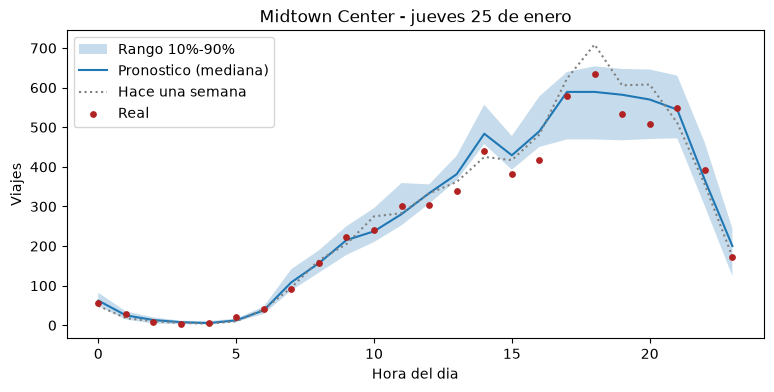

Total esperado (p50): 6723 | Total real: 6423


In [12]:
# Un dia de la semana de prueba en una zona, como lo mostrara la app
resultado = test[["PULocationID", "hora", "viajes", "lag_168"]].copy()
resultado[["p10", "p50", "p90"]] = pred_test[:, [0, 4, 8]]

dia = resultado[(resultado["PULocationID"] == 161) & (resultado["hora"].dt.date == pd.Timestamp("2024-01-25").date())]
horas_dia = dia["hora"].dt.hour

plt.figure(figsize=(9, 4))
plt.fill_between(horas_dia, dia["p10"], dia["p90"], alpha=0.25, label="Rango 10%-90%")
plt.plot(horas_dia, dia["p50"], label="Pronostico (mediana)")
plt.plot(horas_dia, dia["lag_168"], linestyle=":", color="gray", label="Hace una semana")
plt.scatter(horas_dia, dia["viajes"], color="firebrick", s=15, label="Real", zorder=3)
plt.title("Midtown Center - jueves 25 de enero")
plt.xlabel("Hora del dia")
plt.ylabel("Viajes")
plt.legend()
plt.show()

print("Total esperado (p50):", round(dia["p50"].sum()), "| Total real:", int(dia["viajes"].sum()))

### Guardar el modelo

In [13]:
# El modelo en el formato binario de XGBoost
modelo.save_model(CARPETA_API / "modelo_pronostico.ubj")

# Las filas que la API necesita: del 25 de enero al 1 de febrero, con sus variables ya calculadas
para_api = demanda[demanda["hora"] >= FIN_TRAIN].merge(nombres, left_on="PULocationID", right_index=True)
para_api = para_api[["PULocationID", "nombre", "distrito", "hora", "viajes"] + VARIABLES]
para_api.to_parquet(CARPETA_API / "demanda.parquet", index=False)

tamano = (CARPETA_API / "modelo_pronostico.ubj").stat().st_size / 1e6
print(f"Modelo: {tamano:.1f} MB | demanda.parquet: {len(para_api)} filas")

Modelo: 8.4 MB | demanda.parquet: 11136 filas


### Prueba de carga

In [14]:
# Prueba: carga de el modelo como lo haria la API y comprobar que predice lo mismo
copia = xgb.XGBRegressor()
copia.load_model(CARPETA_API / "modelo_pronostico.ubj")
leido = pd.read_parquet(CARPETA_API / "demanda.parquet")

print("Tipo de la columna zona al leer el parquet:", leido["zona"].dtype)

# El parquet no guarda la categoria, hay que volver a crearla con las mismas zonas del entrenamiento
leido["zona"] = pd.Categorical(leido["PULocationID"], categories=sorted(leido["PULocationID"].unique().tolist()))
print("Despues de convertirla:", leido["zona"].dtype)

filas_test = leido[leido["hora"] < FIN_ENERO]
iguales = np.allclose(predecir(copia, filas_test), pred_test, atol=1e-3)
print("El modelo guardado predice lo mismo?", iguales)

Tipo de la columna zona al leer el parquet: int64
Despues de convertirla: category


El modelo guardado predice lo mismo? True


## 2. Segmentacion de zonas

### Filtrar viajes y elegir las zonas

In [15]:
# Para distancia y tarifa no sirven los viajes con valores cero o negativos
validos = viajes[(viajes["trip_distance"] > 0) & (viajes["fare_amount"] > 0)]
validos = validos[~validos["PULocationID"].isin(ZONAS_DESCONOCIDAS)]
print("Viajes descartados por distancia o tarifa:", len(viajes) - len(validos))

conteo_seg = validos["PULocationID"].value_counts()
zonas_seg = conteo_seg[conteo_seg >= 500].index
seg = validos[validos["PULocationID"].isin(zonas_seg)].copy()
print("Zonas que se segmentan:", len(zonas_seg))

Viajes descartados por distancia o tarifa: 105288


Zonas que se segmentan: 90


### Una fila por zona

In [16]:
hora = seg["tpep_pickup_datetime"].dt.hour
seg["fin_de_semana"] = seg["tpep_pickup_datetime"].dt.dayofweek >= 5
seg["manana"] = hora.between(6, 9)        # de 6 a 10 h
seg["tarde"] = hora.between(16, 19)       # de 16 a 20 h
seg["noche"] = (hora >= 22) | (hora <= 4) # de 22 a 5 h

# Una fila por zona 
# El promedio de True/False es el porcentaje de True
perfil = seg.groupby("PULocationID").agg(
    viajes=("trip_distance", "size"),
    distancia_mediana=("trip_distance", "median"),
    tarifa_mediana=("fare_amount", "median"),
    propina_mediana=("tip_amount", "median"),
    pct_fin_de_semana=("fin_de_semana", "mean"),
    pct_manana=("manana", "mean"),
    pct_tarde=("tarde", "mean"),
    pct_noche=("noche", "mean"),
)
perfil["viajes_por_dia"] = perfil["viajes"] / 31
perfil["log_viajes_por_dia"] = np.log10(perfil["viajes_por_dia"])
perfil = perfil.join(nombres)
perfil.sort_values("viajes", ascending=False).head().round(3)

,viajes,distancia_mediana,tarifa_mediana,propina_mediana,pct_fin_de_semana,pct_manana,pct_tarde,pct_noche,viajes_por_dia,log_viajes_por_dia,nombre,distrito
PULocationID,,,,,,,,,,,,
161,140140,1.54,12.1,2.94,0.175,0.070,0.350,0.092,4520.645,3.655,Midtown Center,Manhattan
237,140120,1.23,10.0,2.52,0.197,0.122,0.278,0.070,4520.000,3.655,Upper East Side South,Manhattan
132,138450,17.45,70.0,10.00,0.257,0.117,0.272,0.203,4466.129,3.650,JFK Airport,Queens
236,133961,1.40,10.7,2.52,0.203,0.174,0.270,0.038,4321.323,3.636,Upper East Side North,Manhattan
162,104345,1.52,12.1,2.88,0.179,0.138,0.324,0.085,3365.968,3.527,Midtown East,Manhattan


### Escalar y elegir k

2    0.344
3    0.377
4    0.414
5    0.394
6    0.355
7    0.311
dtype: float64


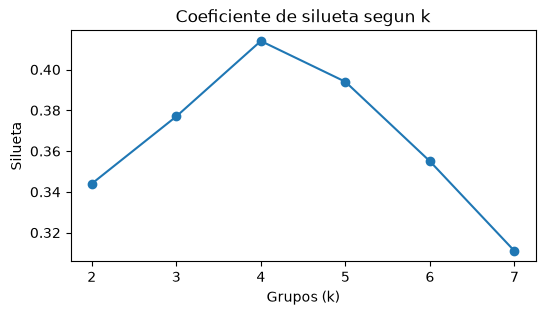

In [17]:
VARS_SEG = ["log_viajes_por_dia", "distancia_mediana", "tarifa_mediana", "propina_mediana",
            "pct_fin_de_semana", "pct_manana", "pct_tarde", "pct_noche"]
X_seg = StandardScaler().fit_transform(perfil[VARS_SEG])

siluetas = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_seg)
    siluetas[k] = silhouette_score(X_seg, etiquetas)
siluetas = pd.Series(siluetas).round(3)
print(siluetas)

plt.figure(figsize=(6, 3))
plt.plot(siluetas.index, siluetas.values, marker="o")
plt.title("Coeficiente de silueta segun k")
plt.xlabel("Grupos (k)")
plt.ylabel("Silueta")
plt.show()

### K-Means con 4 grupos

In [18]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
perfil["grupo_num"] = km.fit_predict(X_seg)

# Perfil promedio de cada grupo (en las unidades originales)
medias = perfil.groupby("grupo_num")[VARS_SEG + ["viajes_por_dia"]].mean()
medias["zonas"] = perfil["grupo_num"].value_counts()
medias.round(3)

,log_viajes_por_dia,distancia_mediana,tarifa_mediana,propina_mediana,pct_fin_de_semana,pct_manana,pct_tarde,pct_noche,viajes_por_dia,zonas
grupo_num,,,,,,,,,,
0,1.554,4.196,23.769,0.303,0.239,0.256,0.183,0.153,47.585,30
1,2.323,2.639,16.728,1.814,0.436,0.073,0.159,0.480,674.022,12
2,3.052,1.919,13.293,2.740,0.247,0.128,0.279,0.127,1687.024,44
3,2.782,12.620,55.225,8.762,0.232,0.134,0.267,0.159,1926.444,4


### Grupos por tipo de perfil

In [19]:
# Nombrar por perfil
pendientes = medias.copy()
nombre_grupo = {}

g = pendientes["distancia_mediana"].idxmax()        # viajes mas largos
nombre_grupo[g] = "Aeropuertos"
pendientes = pendientes.drop(g)

g = pendientes["pct_noche"].idxmax()                # mas viajes de noche
nombre_grupo[g] = "Vida nocturna"
pendientes = pendientes.drop(g)

g = pendientes["log_viajes_por_dia"].idxmax()       # mas viajes por dia
nombre_grupo[g] = "Manhattan central"
pendientes = pendientes.drop(g)

nombre_grupo[pendientes.index[0]] = "Barrios periféricos"

perfil["grupo"] = perfil["grupo_num"].map(nombre_grupo)
perfil.groupby("grupo").agg(
    zonas=("nombre", "size"),
    viajes_al_dia=("viajes_por_dia", "sum"),
    distancia=("distancia_mediana", "median"),
    noche=("pct_noche", "median"),
).round(2)

,zonas,viajes_al_dia,distancia,noche
grupo,,,,
Aeropuertos,4,7705.77,11.84,0.15
Barrios periféricos,30,1427.55,3.60,0.15
Manhattan central,44,74229.06,1.60,0.13
Vida nocturna,12,8088.26,2.09,0.50


### PCA de zonas

In [20]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
componentes = pca.fit_transform(X_seg)
perfil["pc1"], perfil["pc2"] = componentes[:, 0], componentes[:, 1]

varianza = pca.explained_variance_ratio_
print(f"Componente 1: {varianza[0]:.1%} | Componente 2: {varianza[1]:.1%} | Juntas: {varianza.sum():.1%}")

# Que variables pesan en cada componente
pd.DataFrame(pca.components_.T, index=VARS_SEG, columns=["pc1", "pc2"]).round(2)

Componente 1: 36.3% | Componente 2: 29.6% | Juntas: 65.9%


,pc1,pc2
log_viajes_por_dia,0.51,-0.12
distancia_mediana,-0.34,-0.22
tarifa_mediana,-0.37,-0.20
propina_mediana,0.31,-0.24
pct_fin_de_semana,0.10,0.58
pct_manana,-0.43,-0.23
pct_tarde,0.44,-0.33
pct_noche,-0.03,0.58


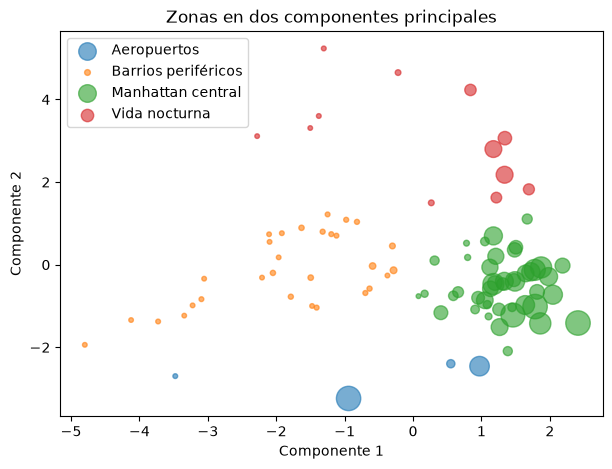

In [21]:
plt.figure(figsize=(7, 5))
for grupo, datos in perfil.groupby("grupo"):
    plt.scatter(datos["pc1"], datos["pc2"], s=datos["viajes_por_dia"] / 15 + 10, alpha=0.6, label=grupo)
plt.title("Zonas en dos componentes principales")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend()
plt.show()

### Guardar la segmentacion

In [22]:
# Proporcion de viajes en cada hora del dia (24 valores por zona) para los mini graficos
por_hora = seg.groupby(["PULocationID", seg["tpep_pickup_datetime"].dt.hour]).size().unstack(fill_value=0)
por_hora = por_hora.div(por_hora.sum(axis=1), axis=0)
por_hora.columns = [f"h{h:02d}" for h in por_hora.columns]

zonas_segmentadas = perfil.join(por_hora).reset_index().rename(columns={"PULocationID": "zona_id"})
zonas_segmentadas = zonas_segmentadas.drop(columns=["grupo_num"])
zonas_segmentadas.to_csv(CARPETA_APP_DATA / "zonas_segmentadas.csv", index=False)

siluetas.rename_axis("k").rename("silueta").reset_index().to_csv(CARPETA_APP_DATA / "siluetas.csv", index=False)
print(zonas_segmentadas.shape)

(90, 40)


### cifras de la ficha

In [23]:
resultado = test[["PULocationID", "hora", "viajes", "lag_24", "lag_168"]].copy()
resultado[[f"p{int(q * 100)}" for q in CUANTILES]] = pred_test
resultado["error_modelo"] = (resultado["viajes"] - resultado["p50"]).abs()
resultado["error_semana"] = (resultado["viajes"] - resultado["lag_168"]).abs()
resultado["dentro_rango"] = (resultado["viajes"] >= resultado["p10"]) & (resultado["viajes"] <= resultado["p90"])

grupo_de_zona = perfil["grupo"]
resultado["grupo"] = resultado["PULocationID"].map(grupo_de_zona)
print("Zonas pronosticadas sin grupo:", resultado["grupo"].isna().sum())

por_grupo = resultado.groupby("grupo").agg(
    zonas=("PULocationID", "nunique"),
    error_modelo=("error_modelo", "mean"),
    error_semana=("error_semana", "mean"),
    viajes_por_hora=("viajes", "mean"),
    cobertura=("dentro_rango", "mean"),
)
por_grupo["error_relativo"] = por_grupo["error_modelo"] / por_grupo["viajes_por_hora"]
por_grupo.round(3)

Zonas pronosticadas sin grupo: 0


,zonas,error_modelo,error_semana,viajes_por_hora,cobertura,error_relativo
grupo,,,,,,
Aeropuertos,3,18.227,20.056,100.996,0.813,0.180
Barrios periféricos,4,2.419,3.051,6.690,0.853,0.362
Manhattan central,43,12.512,12.661,78.834,0.801,0.159
Vida nocturna,8,8.948,9.042,48.471,0.824,0.185


### Cobertura por zona y error por dia

In [24]:
cobertura_zona = resultado.groupby("PULocationID")["dentro_rango"].mean()
print(f"Cobertura por zona: de {cobertura_zona.min():.0%} a {cobertura_zona.max():.0%}")

# Error dia por dia de la semana de prueba
por_dia = resultado.groupby(resultado["hora"].dt.date).agg(
    error_modelo=("error_modelo", "mean"),
    error_semana=("error_semana", "mean"),
    cobertura=("dentro_rango", "mean"),
)
por_dia.round(3)

Cobertura por zona: de 61% a 89%


,error_modelo,error_semana,cobertura
hora,,,
2024-01-25,10.390,11.524,0.804
2024-01-26,11.020,12.590,0.795
2024-01-27,14.202,15.400,0.774
2024-01-28,14.053,13.564,0.774
2024-01-29,12.198,8.766,0.839
2024-01-30,9.743,10.801,0.850
2024-01-31,9.733,10.527,0.823


### Valores SHAP

In [25]:
# Contribuciones SHAP (pred_contribs=True)
datos_test = xgb.DMatrix(test[VARIABLES], enable_categorical=True)
contrib = modelo.get_booster().predict(datos_test, pred_contribs=True)
print("Forma de las contribuciones:", contrib.shape)

# Nos quedamos con la mediana (p50, el cuantil numero 4) y sin la ultima columna (el valor base)
contrib_p50 = contrib[:, 4, :-1] if contrib.ndim == 3 else contrib[:, :-1]
importancia = pd.Series(np.abs(contrib_p50).mean(axis=0), index=VARIABLES).sort_values(ascending=False)
importancia.round(2)

Forma de las contribuciones: (9744, 9, 11)


lag_168          31.360001
lag_24           16.770000
zona              5.040000
lag_169           4.410000
lag_167           2.850000
hora_del_dia      2.220000
dia_semana        2.060000
media_dia_ant     1.030000
lag_48            0.940000
feriado           0.300000
dtype: float32

### Guardar metricas.json

In [26]:
metricas = {
    "zonas_pronostico": len(zonas_pronostico),
    "zonas_segmentadas": int(len(perfil)),
    "horas_prueba": int(len(test)),
    "filas_entrenamiento": int(len(train)),
    "cuantiles": CUANTILES,
    "errores": {k: round(float(v), 2) for k, v in errores.items()},
    "mejora_vs_semana": round(float(mejora), 3),
    "cobertura": round(float(cobertura), 3),
    "cobertura_zona_min": round(float(cobertura_zona.min()), 3),
    "cobertura_zona_max": round(float(cobertura_zona.max()), 3),
    "por_grupo": por_grupo.round(3).reset_index().to_dict(orient="records"),
    "por_dia": por_dia.round(3).rename(index=str).reset_index(names="fecha").to_dict(orient="records"),
    "importancia": importancia.round(3).to_dict(),
    "pca_varianza": [round(float(v), 3) for v in varianza],
    "k_elegido": K,
}
with open(CARPETA_APP_DATA / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)
print(json.dumps(metricas["errores"], ensure_ascii=False), metricas["cobertura"])

{"Igual que ayer": 21.29, "Igual que hace una semana": 11.88, "Modelo (mediana)": 11.62} 0.808
